# Commuting flows from WorldCommuting-OD: Helsinki and Santiago

A first look at the global synthetic commuting dataset of Rong, Ding, Li & Li,
*A Global Intra-city Commuting Origin-Destination Flow Dataset for Urban
Sustainable Development* (Scientific Data 13:1269, 2026,
doi:10.1038/s41597-026-07279-z; repository
`github.com/tsinghua-fib-lab/WorldCommuting-OD`). The flows are generated by a
graph diffusion model (WEDAN) trained on US tract-level commuting, from
WorldPop population, OpenStreetMap points of interest and satellite imagery.
Licence CC BY-NC-ND 4.0.

Each city ships one spatial division and one matrix:

| File | Content |
|---|---|
| `CityAndRegionSplit/<city>/regions.shp` | The city split into square grid cells clipped to the city boundary, in the city's UTM zone |
| `CommutingODFlows/<city>/generation.npy` | A regions × regions matrix; element `[i, j]` is the number of residents of region `i` commuting to work in region `j` |

The grid size is 5 % of the city boundary length, bounded to 0.5 to 5 km, so
the cell size follows the city's extent and there is **no finer level to
choose from**: Helsinki comes at 1.7 km cells, Santiago at 3.8 km. The
diagonal of both matrices is zero, so commuting inside a cell is not part of
the data.

| Step | Output |
|---|---|
| 1. Download | The two city folders under `/scratch/project_2010423/data/worldcommuting-od` |
| 2. Summary | Regions, cell size, commuters, trip-length statistics per city |
| 3. Static maps | Residents, workplaces and the strongest flows per city |
| 4. Interactive maps | `figures/03.1-flows-helsinki.html` and `figures/03.1-flows-santiago.html` |
| 5. Trip lengths | Flow-weighted distance distributions, both cities on one axis |

In [1]:
import json
import urllib.request
from pathlib import Path

import folium
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from shapely.geometry import LineString

## Parameters

Santiago has four namesakes in the repository; `GHSL-58_CHL_Santiago` is the
Chilean capital. The flow maps draw the strongest origin-destination pairs
only, the rest would be an unreadable tangle.

In [2]:
DATA = Path("/scratch/project_2010423/data/worldcommuting-od")
REPOSITORY = "tsinghua-fib-lab/WorldCommuting-OD"
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

CITIES = {
    "helsinki": "944_FI_Helsinki",
    "santiago": "GHSL-58_CHL_Santiago",
}
PARAMETERS = {
    "cities": CITIES,
    # Strongest OD pairs drawn on the static flow maps.
    "top_flows_static": 400,
    # Strongest OD pairs drawn on the interactive maps.
    "top_flows_interactive": 600,
}
COLOURS = {"helsinki": "#2a78d6", "santiago": "#eb6834"}

## 1. Download

The dataset is stored as plain files in the GitHub repository, so one city is
a handful of files fetched through the contents API. Files already present
with the right size are kept.

In [3]:
def fetch_city(city_id):
    """Download one city's region split and OD matrix; returns the city folder."""
    api = f"https://api.github.com/repos/{REPOSITORY}/contents"
    for part in ("CityAndRegionSplit", "CommutingODFlows"):
        target = DATA / city_id / part
        target.mkdir(parents=True, exist_ok=True)
        with urllib.request.urlopen(f"{api}/{part}/{city_id}") as response:
            listing = json.load(response)
        for entry in listing:
            path = target / entry["name"]
            present = path.exists() and path.stat().st_size == entry["size"]
            if entry["type"] == "file" and not present:
                urllib.request.urlretrieve(entry["download_url"], path)
    return DATA / city_id


def load_city(city_id):
    """Regions with their row and column totals, and the OD matrix as floats."""
    folder = fetch_city(city_id)
    regions = gpd.read_file(folder / "CityAndRegionSplit" / "regions.shp")
    flows = np.load(folder / "CommutingODFlows" / "generation.npy").astype(float)
    assert len(regions) == flows.shape[0] == flows.shape[1]
    regions["region"] = np.arange(len(regions))
    regions["residents"] = flows.sum(axis=1)
    regions["workers"] = flows.sum(axis=0)
    regions["area_km2"] = regions.area / 1e6
    centroids = regions.geometry.centroid
    regions["x"], regions["y"] = centroids.x, centroids.y
    return regions, flows


def od_table(regions, flows):
    """The non-zero OD pairs as a long table with centroid-to-centroid distance."""
    origin, destination = np.nonzero(flows)
    x, y = regions["x"].to_numpy(), regions["y"].to_numpy()
    return pd.DataFrame({
        "origin": origin,
        "destination": destination,
        "flow": flows[origin, destination],
        "distance_km": np.hypot(x[destination] - x[origin], y[destination] - y[origin]) / 1000,
    })


cities = {}
for name, city_id in CITIES.items():
    regions, flows = load_city(city_id)
    cities[name] = {"regions": regions, "flows": flows, "od": od_table(regions, flows)}
    print(f"{name:9} {city_id:22} {len(regions):4} regions, {regions.crs}, {flows.sum():,.0f} commuters")

helsinki  944_FI_Helsinki         286 regions, EPSG:32635, 1,622,883 commuters


santiago  GHSL-58_CHL_Santiago    248 regions, EPSG:32719, 2,359,627 commuters


## 2. Summary

Cell size is the side of a full grid cell; the clipped cells on the boundary
are smaller. Distances are between cell centroids, so they understate short
trips and ignore the missing intra-cell commuting entirely.

In [4]:
def weighted_quantile(values, weights, quantile):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, quantile)]


summary = {}
for name, city in cities.items():
    regions, flows, od = city["regions"], city["flows"], city["od"]
    distance, weight = od["distance_km"].to_numpy(), od["flow"].to_numpy()
    summary[name] = {
        "regions": len(regions),
        "cell_side_km": np.sqrt(regions["area_km2"].max()),
        "area_km2": regions["area_km2"].sum(),
        "crs": str(regions.crs),
        "commuters": flows.sum(),
        "nonzero_pairs": len(od),
        "pairs_with_flow_share": len(od) / flows.size,
        "intra_cell_share": np.trace(flows) / flows.sum(),
        "largest_flow": flows.max(),
        "mean_distance_km": np.average(distance, weights=weight),
        "median_distance_km": weighted_quantile(distance, weight, 0.5),
        "p90_distance_km": weighted_quantile(distance, weight, 0.9),
        "max_workers_per_resident": (regions["workers"] / regions["residents"].replace(0, np.nan)).max(),
    }
pd.DataFrame(summary).round(2)

,helsinki,santiago
regions,286,248
cell_side_km,1.703094,3.766348
area_km2,712.029114,2886.956639
crs,EPSG:32635,EPSG:32719
commuters,1622883.0,2359627.0
nonzero_pairs,42286,45605
pairs_with_flow_share,0.516969,0.741496
intra_cell_share,0.0,0.0
largest_flow,895.0,1415.0
mean_distance_km,8.116388,19.261478


## 3. Static maps

Per city: where commuters live (row sums), where they work (column sums), the
ratio of the two (job concentration), and the strongest flows. Flow width is
proportional to the number of commuters on the pair; both directions of a pair
are drawn on top of each other.

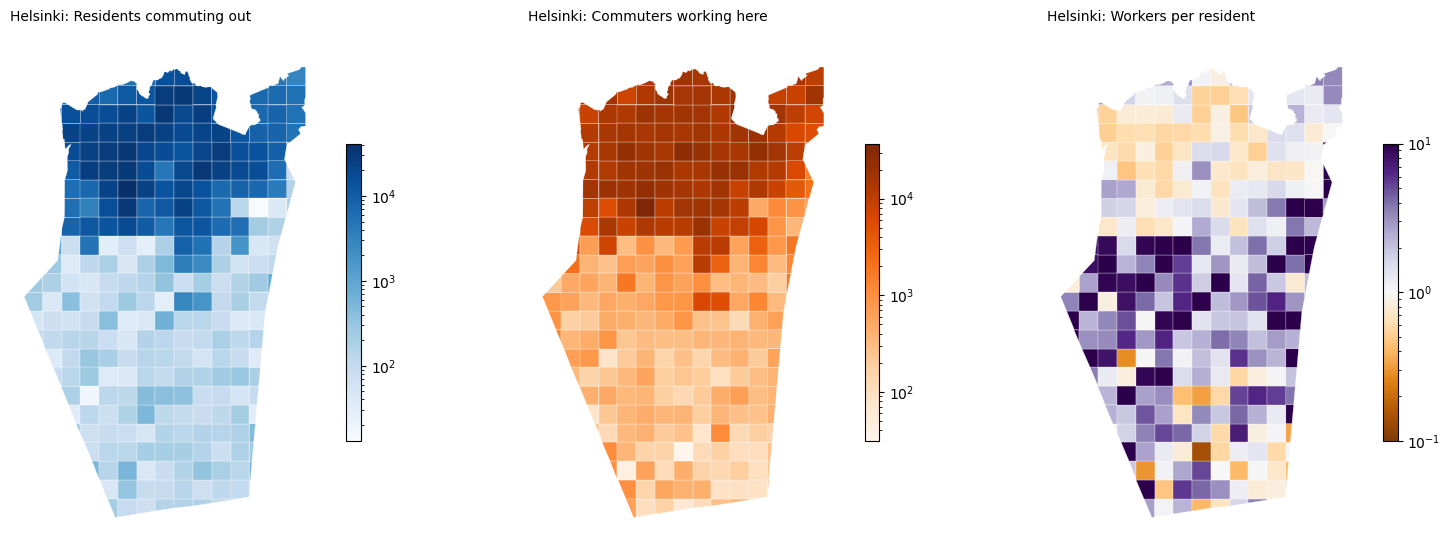

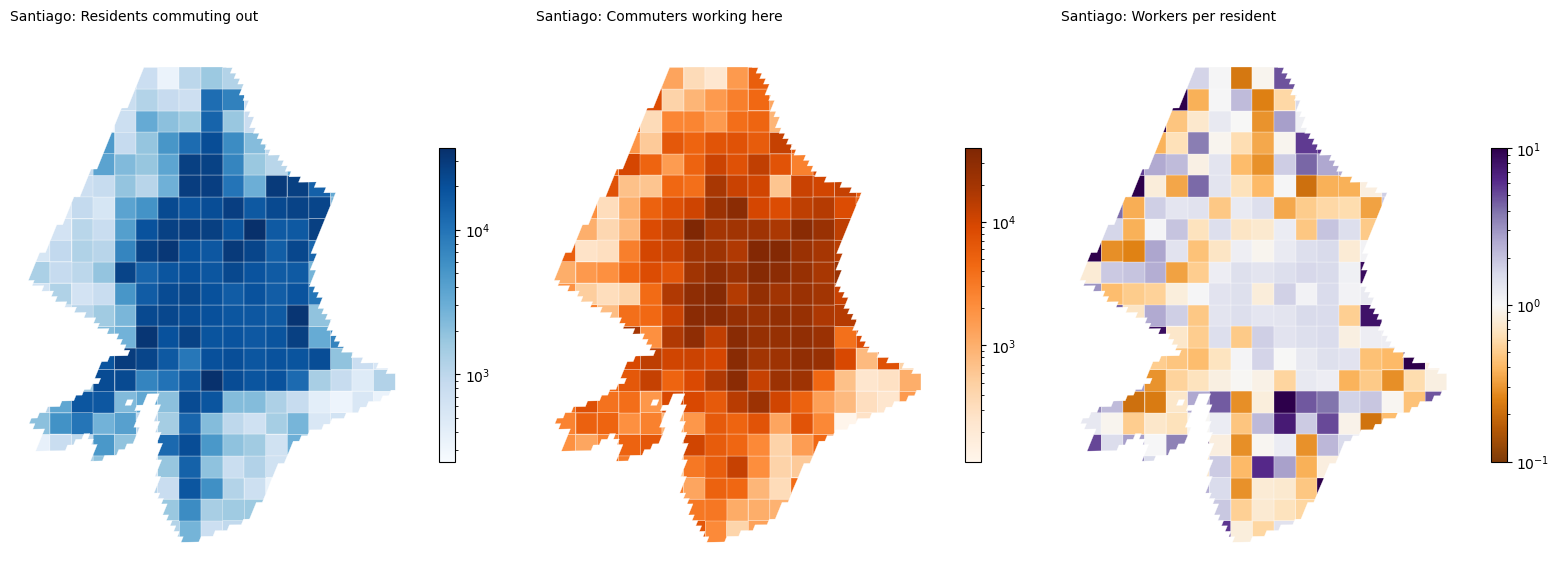

In [5]:
def choropleths(name, city):
    regions = city["regions"]
    balance = regions["workers"] / regions["residents"].replace(0, np.nan)
    panels = [
        ("residents", regions["residents"], "Blues", "Residents commuting out"),
        ("workers", regions["workers"], "Oranges", "Commuters working here"),
        ("balance", balance, "PuOr", "Workers per resident"),
    ]
    figure, axes = plt.subplots(ncols=3, figsize=(16, 5.6))
    for axis, (column, values, cmap, title) in zip(axes, panels):
        frame = regions.assign(value=values.where(values > 0))
        if column == "balance":
            norm = LogNorm(vmin=0.1, vmax=10)
        else:
            norm = LogNorm(vmin=max(values[values > 0].min(), 1), vmax=values.max())
        frame.plot(column="value", ax=axis, cmap=cmap, norm=norm, edgecolor="white", linewidth=0.2,
                   missing_kwds={"color": "#ececea"}, legend=True, legend_kwds={"shrink": 0.6})
        axis.set_title(f"{name.title()}: {title}", loc="left", fontsize=10)
        axis.set_axis_off()
    figure.tight_layout()
    return figure


for name, city in cities.items():
    choropleths(name, city)

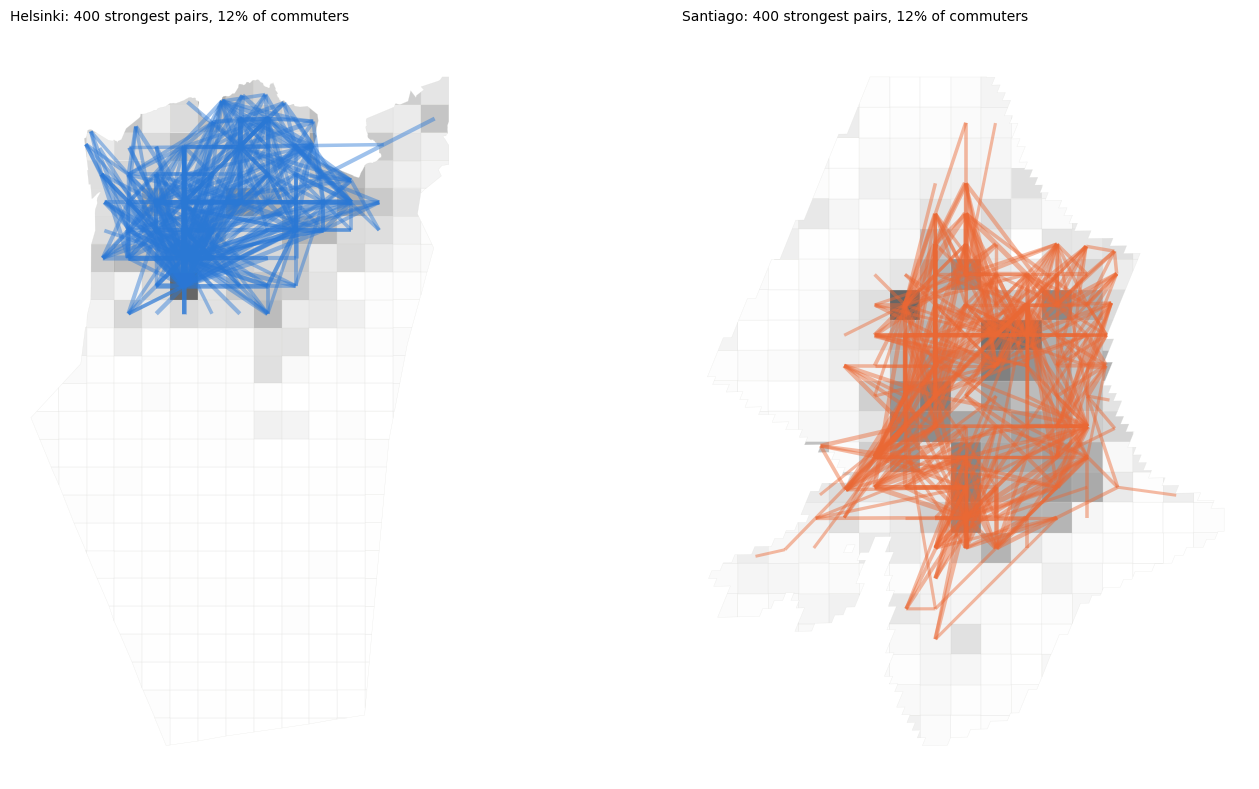

In [6]:
def flow_map(axis, name, city, top):
    regions, od = city["regions"], city["od"]
    strongest = od.nlargest(top, "flow")
    x, y = regions["x"].to_numpy(), regions["y"].to_numpy()
    origin, destination = strongest["origin"].to_numpy(), strongest["destination"].to_numpy()
    segments = np.stack(
        [np.column_stack([x[origin], y[origin]]), np.column_stack([x[destination], y[destination]])], axis=1
    )
    widths = 0.2 + 5 * strongest["flow"].to_numpy() / strongest["flow"].max()
    regions.plot(ax=axis, column="workers", cmap="Greys", edgecolor="#d8d8d4", linewidth=0.2, alpha=0.6)
    axis.add_collection(LineCollection(segments, linewidths=widths, colors=COLOURS[name], alpha=0.45))
    share = strongest["flow"].sum() / od["flow"].sum()
    axis.set_title(f"{name.title()}: {top} strongest pairs, {share:.0%} of commuters", loc="left", fontsize=10)
    axis.set_axis_off()


figure, axes = plt.subplots(ncols=2, figsize=(16, 8))
for axis, (name, city) in zip(axes, cities.items()):
    flow_map(axis, name, city, PARAMETERS["top_flows_static"])
figure.tight_layout()

## 4. Interactive maps

One Leaflet map per city with the regions coloured by residents, a workplace
layer, and the strongest flows as lines with a tooltip giving the pair and its
commuters. Layers can be switched in the control at the top right. The maps are
saved next to the notebook and the Helsinki one is shown inline.

In [7]:
def interactive_map(name, city, top):
    regions, od = city["regions"], city["od"]
    geographic = regions.to_crs("EPSG:4326")
    centre = geographic.geometry.union_all().centroid
    # Esri tiles serve without a key or referer; OpenStreetMap blocks locally opened files.
    figure = folium.Map(location=[centre.y, centre.x], zoom_start=10, tiles="Esri.WorldGrayCanvas")
    folium.TileLayer("Esri.WorldStreetMap", name="Esri streets", show=False).add_to(figure)
    folium.TileLayer("OpenStreetMap", name="OpenStreetMap", show=False).add_to(figure)

    for column, cmap, label in [("residents", "Blues", "Residents"), ("workers", "Oranges", "Workplaces")]:
        layer = folium.Choropleth(
            geo_data=geographic[["region", "residents", "workers", "geometry"]].to_json(),
            data=geographic[["region", column]],
            columns=["region", column],
            key_on="feature.properties.region",
            fill_color=cmap,
            fill_opacity=0.6,
            line_opacity=0.2,
            legend_name=f"{label} ({name.title()})",
            name=label,
            show=column == "residents",
        )
        layer.add_to(figure)
        folium.GeoJsonTooltip(fields=["region", "residents", "workers"]).add_to(layer.geojson)

    strongest = od.nlargest(top, "flow")
    centroids = gpd.GeoSeries.from_xy(regions["x"], regions["y"], crs=regions.crs).to_crs("EPSG:4326")
    lines = gpd.GeoDataFrame(
        strongest.assign(
            geometry=[
                LineString([(centroids.x[o], centroids.y[o]), (centroids.x[d], centroids.y[d])])
                for o, d in zip(strongest["origin"], strongest["destination"])
            ]
        ),
        crs="EPSG:4326",
    )
    scale = 8 / strongest["flow"].max()
    folium.GeoJson(
        lines.to_json(),
        name=f"{top} strongest flows",
        style_function=lambda feature: {
            "color": COLOURS[name],
            "weight": 0.5 + scale * feature["properties"]["flow"],
            "opacity": 0.5,
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["origin", "destination", "flow", "distance_km"],
            aliases=["home region", "work region", "commuters", "distance km"],
        ),
    ).add_to(figure)
    folium.LayerControl(collapsed=False).add_to(figure)
    return figure


maps = {}
for name, city in cities.items():
    maps[name] = interactive_map(name, city, PARAMETERS["top_flows_interactive"])
    maps[name].save(FIGURES / f"03.1-flows-{name}.html")
maps["helsinki"]

In [8]:
maps["santiago"]

## 5. Trip lengths

Flow-weighted distribution of centroid-to-centroid commuting distance. The
Santiago histogram cannot resolve anything below its 3.8 km cell size, and
neither city has the intra-cell trips, so the left tail of both is missing by
construction.

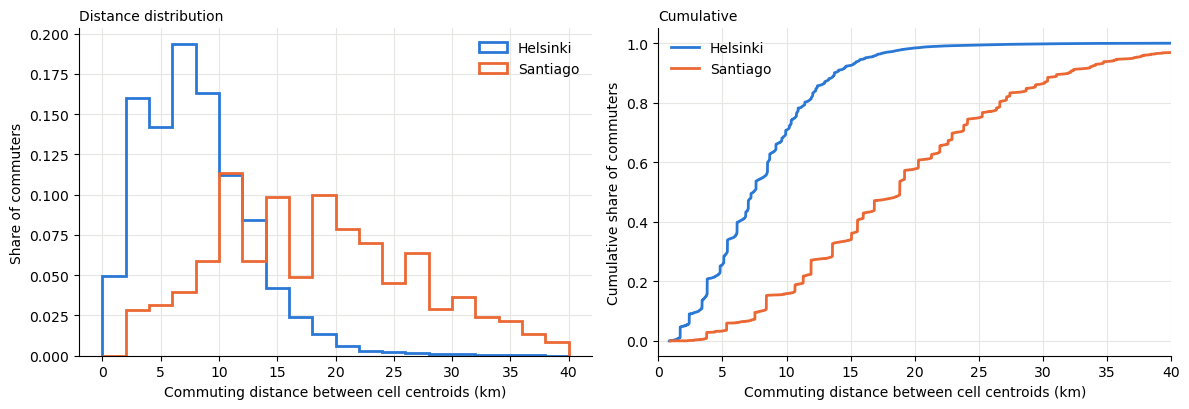

In [9]:
figure, (left, right) = plt.subplots(ncols=2, figsize=(12, 4.2))
edges = np.arange(0, 42, 2)
for name, city in cities.items():
    od = city["od"]
    weights = od["flow"] / od["flow"].sum()
    left.hist(od["distance_km"], bins=edges, weights=weights, histtype="step", linewidth=2,
              color=COLOURS[name], label=name.title())
    ordered = od.sort_values("distance_km")
    right.plot(ordered["distance_km"], ordered["flow"].cumsum() / ordered["flow"].sum(),
               color=COLOURS[name], linewidth=2, label=name.title())
left.set_xlabel("Commuting distance between cell centroids (km)")
left.set_ylabel("Share of commuters")
left.set_title("Distance distribution", loc="left", fontsize=10)
right.set_xlabel("Commuting distance between cell centroids (km)")
right.set_ylabel("Cumulative share of commuters")
right.set_xlim(0, 40)
right.set_title("Cumulative", loc="left", fontsize=10)
for axis in (left, right):
    axis.grid(color="#e6e6e3", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)
    axis.legend(frameon=False)
figure.tight_layout()

## 6. Helsinki extent against the project lattice

The Helsinki polygon is the municipality, which includes about 500 km² of
sea, and the grid cuts the water into cells like any other. The model still
assigns residents and jobs to them. The populated H3 lattice of `02.1` tells
land from water: a grid cell that overlaps no inhabited hexagon is a sea cell,
and the share of commuters starting or ending there is the part of the matrix
to discard. The lattice also shows what the dataset leaves out: Espoo, Vantaa
and the rest of the region are outside the municipality boundary.

176 of 286 grid cells overlap no inhabited hexagon
commuters living in them: 3.5%, working in them: 8.1%
flows with both ends on land: 90.4%
inhabited hexagons outside the Helsinki polygon: 724 of 1105, 42% of the lattice population


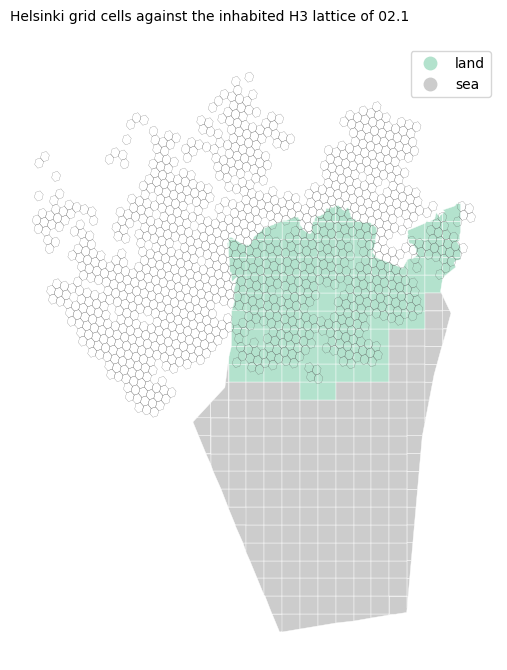

In [10]:
LATTICE = Path("/scratch/project_2010423/carbon-advantage/helsinki/lattice.gpkg")

helsinki = cities["helsinki"]["regions"]
flows = cities["helsinki"]["flows"]
lattice = gpd.read_file(LATTICE).to_crs(helsinki.crs)
inhabited = lattice[lattice["population"] > 0]
on_land = helsinki.intersects(inhabited.geometry.union_all()).to_numpy()
sea = ~on_land
print(f"{sea.sum()} of {len(helsinki)} grid cells overlap no inhabited hexagon")
print(f"commuters living in them: {flows[sea].sum() / flows.sum():.1%}, working in them: {flows[:, sea].sum() / flows.sum():.1%}")
print(f"flows with both ends on land: {flows[np.ix_(on_land, on_land)].sum() / flows.sum():.1%}")
print(f"inhabited hexagons outside the Helsinki polygon: "
      f"{(~inhabited.intersects(helsinki.geometry.union_all())).sum()} of {len(inhabited)}, "
      f"{inhabited.loc[~inhabited.intersects(helsinki.geometry.union_all()), 'population'].sum() / inhabited['population'].sum():.0%} of the lattice population")

figure, axis = plt.subplots(figsize=(8, 8))
helsinki.assign(land=np.where(on_land, "land", "sea")).plot(
    column="land", ax=axis, cmap="Pastel2", edgecolor="white", linewidth=0.3, legend=True, categorical=True
)
inhabited.boundary.plot(ax=axis, color="#555", linewidth=0.15)
axis.set_title("Helsinki grid cells against the inhabited H3 lattice of 02.1", loc="left", fontsize=10)
axis.set_axis_off()

## Reading the result

- The flows are model output, not observed commuting. The model was trained on
  US tract-level data and validated on the US and the UK only (CPC 0.59 and
  0.49); neither Finland nor Chile had any validation. Treat the matrices as a
  prior on the spatial structure of commuting, not as ground truth.
- The totals are not calibrated either: the Helsinki matrix holds 1.6 million
  commuters for a municipality of about 680,000 inhabitants, so only shares
  and relative patterns carry information, never absolute counts.
- The Helsinki extent is the municipality, not the region: 42 % of the
  population on the `02.1` lattice lives outside it, and the sea cells of the
  polygon carry about a tenth of the flows. The Santiago extent is the GHSL
  urban centre, which covers the metropolitan area.
- The cell size is fixed by the city extent. For Helsinki the 1.7 km cells are
  about four times the area of the H3 resolution 8 hexagons of `02.1`; for
  Santiago the 3.8 km cells are coarse enough that the centre falls into a few
  cells.
- Intra-cell commuting is absent (zero diagonal), so short trips are missing
  and every distance statistic above is biased long, more so for Santiago.